In [1]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import tensorflow as tf

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.layers import Input, Dense, Flatten
from keras.utils import to_categorical
from keras.models import Sequential
from sklearn.preprocessing import StandardScaler, LabelEncoder

## Ladataan data

Ladataan data ja muokataan se dataframeksi, että on helpompi tulkita käsiteltävät piirteet ja kohdearvo.

In [3]:
# Asetetaan kerasin seed tasaiseksi tulostenvertailun selkeyttämiseen
keras.utils.set_random_seed(0)

# Datasetin lataus
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, header=None, names=columns)

In [4]:
# tarkistetaan että datasetti latautui oikein
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


## Varmistutaan ettei ole tyhjiä arvoja datassa

In [5]:
# Tarkistetaan tyhjät rivit datasetistä
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

## Jaetaan data piirteisiin ja kohteeseen

Datassa on 4 piirrettä ja 1 kohde. Kohde on nimellä "species". Se helpottaa jakoa.

In [6]:
# Jaetaan kohde y:ksi ja piirteet x:ksi
x = df.drop(columns=["species"])
y = df["species"]

## Tarkastellaan kohdeluokkia

In [7]:
print(df["species"].unique())

<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


## Johtopäätökset

Ei tyhjiä, ei tarvitse niitä korjata datasta. Datassa on 4 piirrettä ja 3 eri kohdeluokkaa. Kohde luokat ovat kirjainjonoja -> ne pitää muokkaa eka numeerisiksi, että voi one-hot enkoodata.

## Tutkitaan maksimi- ja minimiarvoja piirteittäin

Katsotaan jokaisen piirteen maksimit, jotta voidaan päättää tarvitaanko skaalausta.

In [8]:
sepal_length_max = x["sepal_length"].max()
sepal_length_min = x["sepal_length"].min()

sepal_width_max = x["sepal_width"].max()
sepal_width_min = x["sepal_width"].min()

petal_length_max = x["petal_length"].max()
petal_length_min = x["petal_length"].min()

petal_width_max = x["petal_width"].max()
petal_width_min = x["petal_width"].min()

print(f"Verholehden pituus: min {sepal_length_min} cm, max {sepal_length_max} cm")
print(f"Verholehden leveys: min {sepal_width_min} cm, max {sepal_width_max} cm")
print(f"Terälehden pituus: min {petal_length_min} cm, max {petal_length_max} cm")
print(f"Terälehden leveys: min {petal_width_min} cm, max {petal_width_max} cm")

Verholehden pituus: min 4.3 cm, max 7.9 cm
Verholehden leveys: min 2.0 cm, max 4.4 cm
Terälehden pituus: min 1.0 cm, max 6.9 cm
Terälehden leveys: min 0.1 cm, max 2.5 cm


## Johtopäätökset

Datan muuttujien erot on suurehkoja -> tarvitaan skaalausta, jotta suuremmat erot eivät paina mallia väärään suuntaan.

## Datan skaalaus

Valitaan StandardScaler skaalaajaksi. Näin piirteiden keskiarvo on 0 ja keksihajonta 1.

In [9]:
# Standardoidaan piirteet, että keskiarvo on 0 ja keskihajonta on 1
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

## Kohdearvojen käsittely

Ensin LabelEncoderilla numeroidaan kohdearvot numeerisiksi ja sitten one-hot enkoodataan to_categorical endkooderilla

In [10]:
# Muutetaan kohdearvot numeerisiksi
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# One-hot enkoodataan kohdearvot
y_onehot = to_categorical(y_encoded, 3)

## Tarkistetaan onnistuiko muutokset

In [11]:
# Tarkistetaan onnistuiko molemmat skaalaus ja onehot muokkaus lukemalla ekat 5
print("Onehot ekat 5:\n")
print(y_onehot[:5])
print("\n Skaalatut piirteet ekat 5:\n")
print(x_scaled[:5])

Onehot ekat 5:

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]

 Skaalatut piirteet ekat 5:

[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


## Päätetään mallin input arvo

Vaikka tiedetään että on 4 eri piirrettä, varmistetaan se käsittelyn ja skaalauksen jälkeen vielä shape-metodilla.

In [12]:
# Tarkistetaan shape oikean inputin määrittämiseski
x_scaled.shape

(150, 4)

## Johtopäätökset

Enkoodaus onnistui ja 4 eri kohdetta datassa. Skaalaus meni oikein ja saamme mallille paremmat arvot syötettyä.

## Mallinnus ja alustus

Aluksi sekoitetaan piirteet ja kohteet pitäen ne samoissa kohdissa. Datassa nähtiin, että kohdeluokat oli järjestyksessä, näin malli saa sekoitettua dataa jo heti alussa, ettei tule heittoa loss arvoille (Ennen, kun tämän sekoituksen tein, huomasin heittelyä käyrässä alla. Sekoituksen jälkeen oppiminen stabiloitui.)

## Sekoitus

In [13]:
# Sekoitetaan dataa np.random.shufflella

# Luodaan satunnainen järjestys
indices = np.arange(len(x_scaled))
np.random.seed(0)
np.random.shuffle(indices)

# Sekoitetaan piirteet ja kohdearvot samassa järjestyksessä
x_shuffled = x_scaled[indices]
y_shuffled = y_onehot[indices]

## Mallinnus

Alustetaan ensimmäinen malli. Input pysyy kaikissa malleissa samoina ja viimeinen Dense kerron on luokkien mukaan 3 neuronia per 3 kohdeluokkaa. Kokeillaan ensin miten malli toimii neuroneilla 16, 32, 64, 128.

## Alustetaan mallit

In [14]:
# 16 neuronin malli
model16 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(16, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 32 neuronin malli
model32 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(32, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 64 neuronin malli
model64 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(64, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 128 neuronin malli
model128 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(128, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

model_list = [model16, model32, model64, model128]

2026-10-23 14:48:47.447035: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-23 14:48:47.447053: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 14:48:47.447057: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792756127.447066 2127990 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792756127.447081 2127990 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [15]:
# Alustetaan mallit samalla optimoijalla.

for model in model_list:
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

## Epoch määrän valinta käyttäen earlystoppia

Kokeillaan monellako epochilla saadaan tarpeeksi tarkka tulos. Luodaan esin earlystopperi, joka tarkastelee missä vaiheessa validointi häviö alkaa kasvaa. Alussa huomasin paljon heittelyä, joten valitsin patience parametriksi 15, jotta ei pysäytä liian aikaisin

In [16]:
"""# luodaan stopperi datan oppimisen analysoinnin helpottamiseksi

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",     # monitoroi validation lossia
    patience=15,            # 15 peräkkäistä nousua
    restore_best_weights=True
)
"""

'# luodaan stopperi datan oppimisen analysoinnin helpottamiseksi\n\nearly_stop = keras.callbacks.EarlyStopping(\n    monitor="val_loss",     # monitoroi validation lossia\n    patience=15,            # 15 peräkkäistä nousua\n    restore_best_weights=True\n)\n'

In [17]:
import time



# Sovitetaan mallit ja luodaan jokaiselle oma historia.

neurons = 16  # ensimmäisen mallin mukaan ja kertomalla 2 saadaan oikeat nimet malleille

histories = []
training_times = []

for model in model_list:
    start = time.perf_counter()
    history = model.fit(x_shuffled, y_shuffled, epochs=150, validation_split=0.2)
    histories.append(history)
    
    elapsed = time.perf_counter() - start
    training_time = f"Koulutusaika neuroneilla {neurons}: {elapsed:.2f} s"
    training_times.append(training_time)
    neurons *= 2

Epoch 1/150
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.3438 - loss: 1.5051

2026-10-23 14:48:47.708180: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3333 - loss: 1.4329 - val_accuracy: 0.4000 - val_loss: 1.3205
Epoch 2/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3583 - loss: 1.3242 - val_accuracy: 0.4333 - val_loss: 1.2418
Epoch 3/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3750 - loss: 1.2527 - val_accuracy: 0.4333 - val_loss: 1.1797
Epoch 4/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4000 - loss: 1.1943 - val_accuracy: 0.4333 - val_loss: 1.1264
Epoch 5/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4167 - loss: 1.1433 - val_accuracy: 0.4333 - val_loss: 1.0789
Epoch 6/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4667 - loss: 1.0974 - val_accuracy: 0.5000 - val_loss: 1.0353
Epoch 7/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5000 - loss: 1.0546 - val_accuracy: 0.5000 - val_loss: 0.9941
Epoch 8/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5083 - loss: 1.0140 - val_accuracy: 0.5000 - val_loss: 0.9553
Epoc

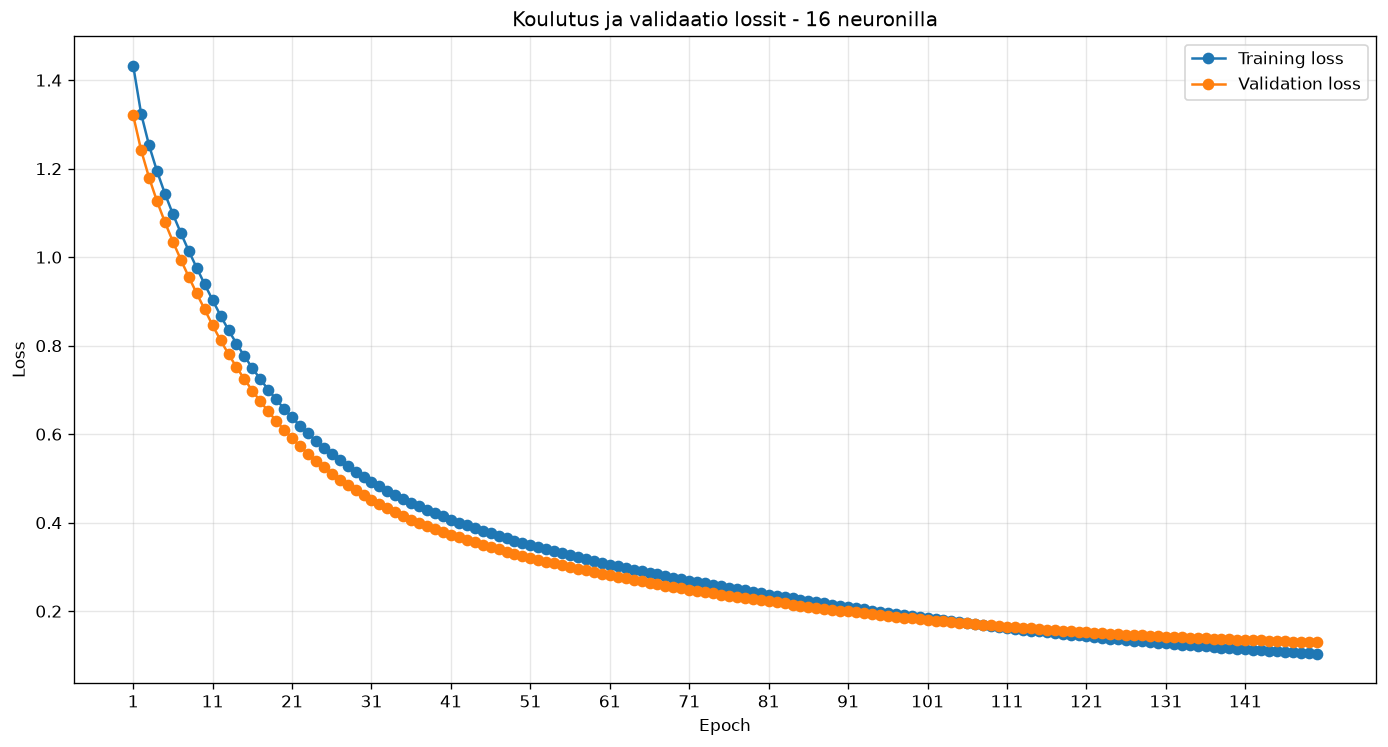

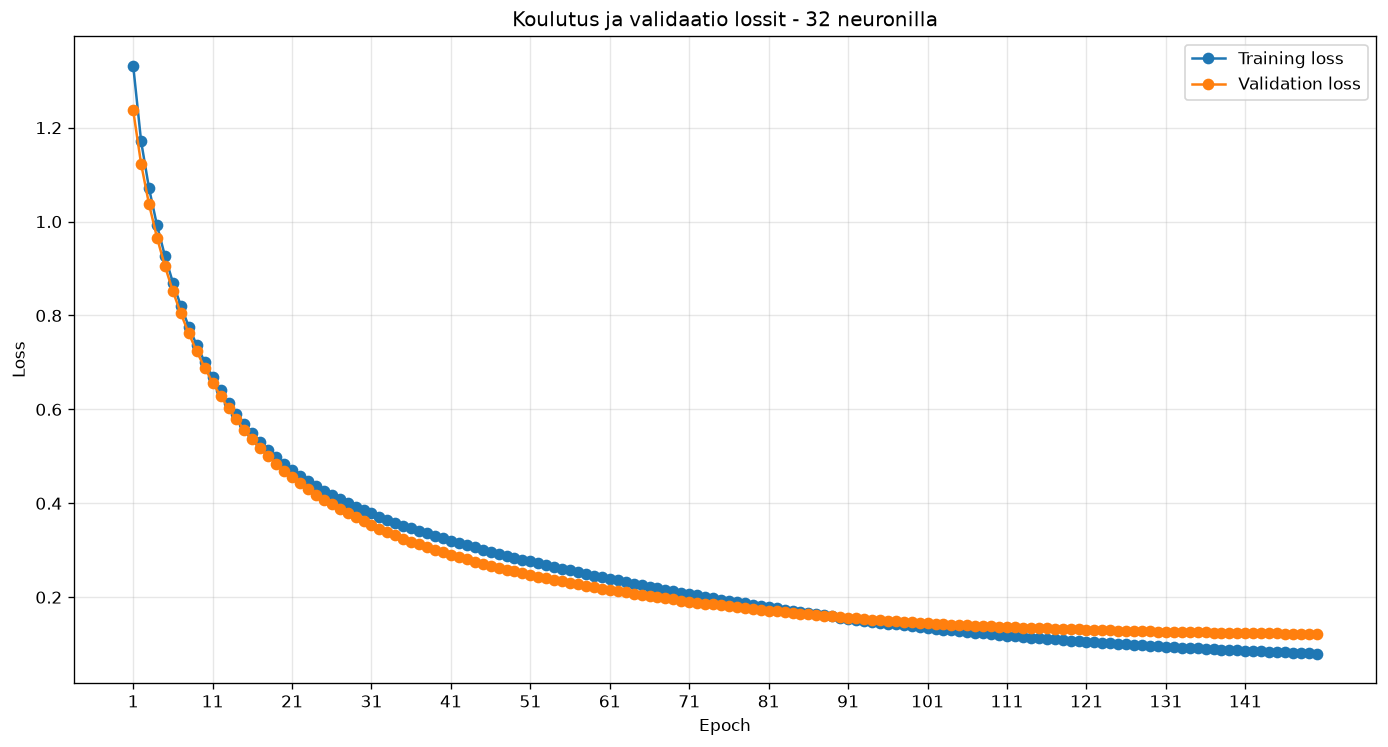

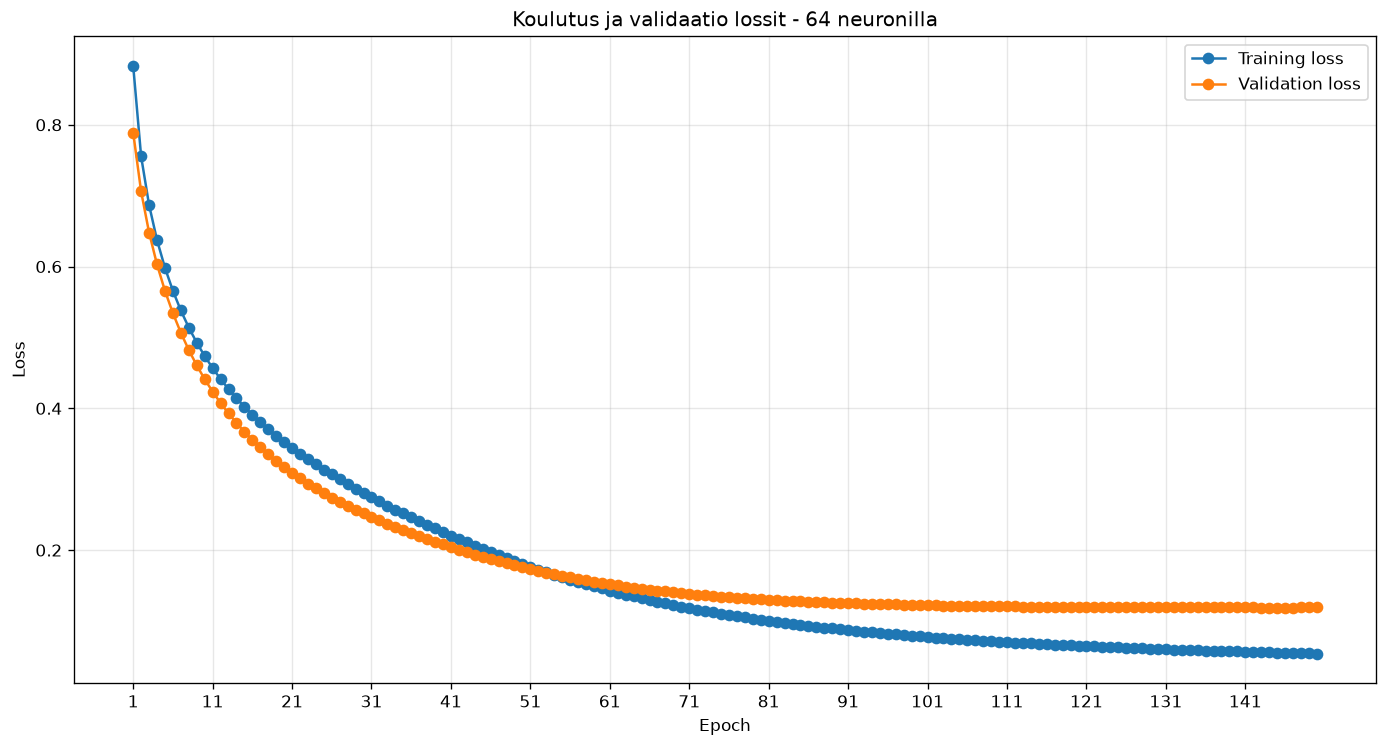

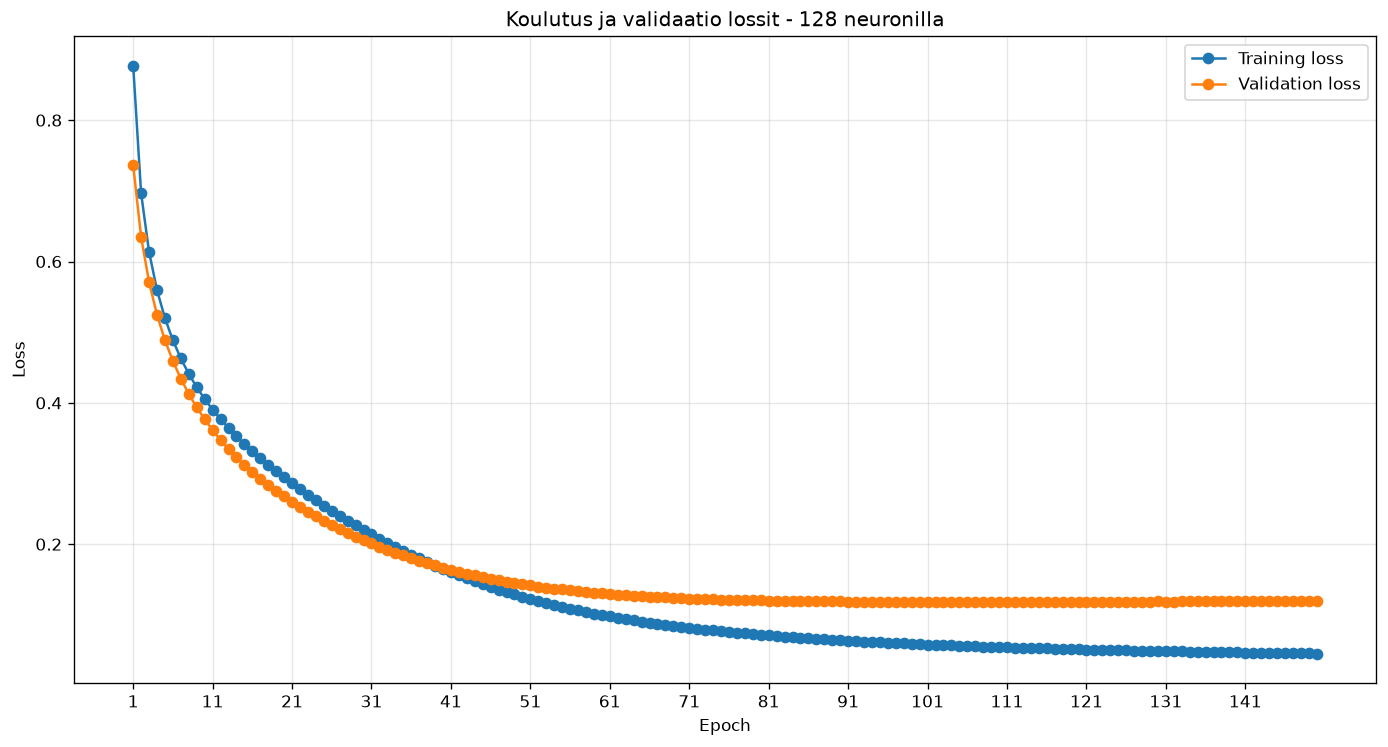

In [18]:
import matplotlib.pyplot as plt

neurons = 16

for history in histories:
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(14, 7), dpi=120)

    plt.plot(epochs, history.history["loss"],
             marker="o", label="Training loss")
    plt.plot(epochs, history.history["val_loss"],
             marker="o", label="Validation loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Koulutus ja validaatio lossit - {neurons} neuronilla")

    plt.xticks(range(1, len(epochs) + 1, 10))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    neurons *= 2

## Suoritusajat

In [19]:
for training_time in training_times:
    print(f"\n{training_time}\n")


Koulutusaika neuroneilla 16: 8.55 s


Koulutusaika neuroneilla 32: 9.13 s


Koulutusaika neuroneilla 64: 9.43 s


Koulutusaika neuroneilla 128: 9.39 s

